# Redundancy Reduction in Bimetallic Nanoparticle Data Sets via Iterative Archetypal Analysis

**author:** Jonathan Yik Chang Ting

**email:** Jonathan.Ting@anu.edu.au

This is a notebook to reduce the redundancy in bimetallic nanoparticle data sets using the iterative archetypal analysis functionalities provided by *archetypes.py*.

## Import Packages

In [1]:
%load_ext autoreload
%autoreload 2

from os import chdir, getcwd
import pickle
import requests

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
from scipy.spatial.distance import cdist
import seaborn as sns
import sklearn
from sklearn.datasets import load_diabetes, make_blobs
from sklearn.metrics import explained_variance_score
from sklearn.model_selection import KFold
from sklearn.preprocessing import StandardScaler

chdir('/scratch/q27/jt5911')
from archetypes import ArchetypalAnalysis, create_simplex_ax, map_alfa_to_simplex, plot_radar_datapoint


# Print package versions for reproducibility
print('Versions of imported libraries:')
print(f"  matplotlib: {mpl.__version__}")
print(f"  numpy: {np.__version__}")
print(f"  pandas: {pd.__version__}")
print(f"  scipy: {scipy.__version__}")
print(f"  seaborn: {sns.__version__}")
print(f"  scikit-learn: {sklearn.__version__}")

Versions of imported libraries:
  matplotlib: 3.8.2
  numpy: 1.26.0
  pandas: 2.1.3
  scipy: 1.11.4
  seaborn: 0.13.0
  scikit-learn: 1.3.2


In [2]:
# General variables
DATA_DIR = f"{getcwd()}/data"
RANDOM_STATE = 42
VERBOSE = True
NUM_JOBS = 48

# Variables specific for figures plotting
DPI = 300
FIG_SIZE = (7, 4)
sns.set_style('ticks')

# Variables specific for splitting data into subsets
SHUFFLE = True  # Whether to shuffle data samples before splitting.

# Variables specific for archetypes.py functionalities
C = 0.0001  # constraint coefficient to ensure that the summation of alpha and beta equals to 1.

# Variables specific for the archetypal analysis algorithm provided by the SPArse Modeling Software (SPAMS) package
ROBUST = False  # Whether to use modified AA algorithm to deal with outliers
TOLERANCE = 0.001  # Threshold to decide when to stop optimisation.
COMPUTE_XTX = False  # Whether to compute X^T * X
STEPS_FISTA = 3  # Number of steps for fast iterative shrinkage-thresholding algorithm
STEPS_AS = 50  # Number of steps for active set algorithm
RANDOM_INIT = False  # Whether to initialise the archetypes randomly

### Arguments Description
- **n_archetypes**: Defines how many archetypes will be extracted. A positive integer. Setting to 1 return the mean of the data set. *Default = 2*.
- **iterative**: Whether to use the iterative or classical approach. *Default = False*.
- **n_subsets**: The number of subsets to split the data into if **iterative** = True. *Default = 10*.
- **shuffle**: Whether to shuffle the data samples before splitting. *Default = True*.
- **only_archetypes**: Whether to stop running when archetypes are computed. Setting to True allows only archetypes and run time to be returned. *Default = False*.
- **C**: the weight on the constraint equation. Inversely proportional to the strength of constraint. *Default = 0.0001*. Constraint Eq.: $$\sum\alpha = 1,$$ $$\sum\beta = 1$$. 

The following arguments are specific to the archetypal analysis algorithm provided by the [SPArse Modeling Software (SPAMS) package](https://thoth.inrialpes.fr/people/mairal/spams/), hence Users are directed to their homepage and the original publication describing the algorithm in "[Fast and Robust Archetypal Analysis for Representation Learning](https://ieeexplore.ieee.org/document/6909588)" for up-to-date and detailed descriptions.
- **robust**
- **tolerance**
- **computeXtX**
- **stepsFISTA**
- **stepsAS**
- **randominit**
- **random_state**
- **numThreads**

### General Functions

In [3]:
def plotAAoutputs(Xscaled, AAclassical, AAiterative,
                  plotSubsets=True, figName='',
                  figSize=(7, 4), dpi=300, verbose=False):
    """Plot the data and archetypes from both approaches."""
    Zclassical, Ziterative = AAclassical.archetypes, AAiterative.archetypes
    # if verbose:
    #     print(f"Archetype set from classical approach:\n{Zclassical}")
    #     print(f"Archetype set from iterative approach:\n{Ziterative}")
    
    plt.figure(figsize=figSize, dpi=dpi)
    if not plotSubsets:
        plt.scatter(Xscaled[:, 0], Xscaled[:, 1], marker='.', s=5) # color='y', 
    else:
        for idxs in AAiterative.subsets_sample_idxs: 
            plt.scatter(Xscaled[idxs, 0], Xscaled[idxs, 1], marker='.', s=5)
    all_subsets_Zs =  np.concatenate(AAiterative.subsets_Zs, axis=1)
    plt.plot(Zclassical[0, :], Zclassical[1, :], 'X', markersize=9, markeredgecolor='k', markeredgewidth=0.8, color='r', alpha=0.5)  # color='m'
    plt.plot(Ziterative[0, :], Ziterative[1, :], 'X', markersize=9, markeredgecolor='k', markeredgewidth=0.8, color='b', alpha=0.5)  # color='c'
    plt.plot(all_subsets_Zs[0, :], all_subsets_Zs[1, :], 'D', markersize=4, markeredgecolor='k', markeredgewidth=0.6, color='y')  # color='b'
    plt.xlabel('Dimension 1')
    plt.ylabel('Dimension 2')
    plt.grid(linestyle='dotted')
    legendEntries = [f"Data Subset {i+1}" for i in range(len(AAiterative.subsets_sample_idxs))] if plotSubsets else ['Data']
    legendEntries += [f"Classical Approach Archetypes, ExpVar: {AAclassical.explained_variance_:.3f}", f"Iterative Approach Archetypes, ExpVar: {AAiterative.explained_variance_:.3f}", 'Archetypes from Split Sets']
    plt.legend(legendEntries, loc='center left', bbox_to_anchor=(1, 0.5), ncol=1, fancybox=True, shadow=False, fontsize='x-small')
    plt.tight_layout()
    plt.savefig(f"figures/AA_{figName}.png")

In [4]:
def runAAonData(Xscaled, numArchetypes=4, numSubsets=[4], runClassical=True, onlyZ=False,
                robust=False, shuffle=True, randomState=42, 
                datasetType='uniformSquare', plotSubsets=True, 
                figSize=(7, 4), dpi=300, verbose=False):
    AAclassical = None
    if runClassical:
        AAclassical = ArchetypalAnalysis(n_archetypes=numArchetypes, iterative=False, robust=robust, only_archetypes=onlyZ,
                                         C=C, tolerance=TOLERANCE, computeXtX=COMPUTE_XTX, stepsFISTA=STEPS_FISTA, stepsAS=STEPS_AS, randominit=RANDOM_INIT, 
                                         random_state=randomState, numThreads=NUM_JOBS)
        AAclassical.fit(Xscaled)
        if verbose:
            print(f"Classical archetypal analysis execution time: {AAclassical.run_time:.3f} s")
    # Elbow plot for iterative approach
    for (i, numSubset) in enumerate(numSubsets):
        AAiterative = ArchetypalAnalysis(n_archetypes=numArchetypes, iterative=True, robust=robust, only_archetypes=onlyZ, n_subsets=numSubset, shuffle=shuffle, 
                                         C=C, tolerance=TOLERANCE, computeXtX=COMPUTE_XTX, stepsFISTA=STEPS_FISTA, stepsAS=STEPS_AS, randominit=RANDOM_INIT, 
                                         random_state=randomState, numThreads=NUM_JOBS)
        AAiterative.fit(Xscaled)
        if verbose:
            print(f"Iterative archetypal analysis {numSubset} subsets execution time: {AAiterative.run_time:.3f} s")
        if not onlyZ:
            colourSubsetsStr = 'colourSubsets' if plotSubsets else 'colourWholeSet'
            plotAAoutputs(Xscaled, AAclassical, AAiterative,
                          plotSubsets=plotSubsets, figName=f"{datasetType}_{numSubset}-fold_{colourSubsetsStr}",
                          figSize=figSize, dpi=dpi, verbose=verbose)
    return AAclassical, AAiterative

The following functionalities are covered:
- extraction of the archetype attributes, 
- mapping of data to the archetype space,
- visualisation of archetype profiles (contributions of the archetypes in describing any other data sample), 
- identification of the most archetypal data samples, 
- visualisation of the data samples and archetypes on parallel axis.

### Load Data

The skeleton dataset will be used for the following demonstration to allow comparison with previous methods. 

The dataset:
- is a real world dataset used for demonstration in [From Spider-Man to Hero -- Archetypal Analysis in R](https://www.jstatsoft.org/article/view/v030i08). 
- was collected by Heinz G et al. in [Exploring Relationships in Body Dimensions](http://www.amstat.org/publications/jse/v11n2/datasets.heinz.html).
- includes 507 samples, of which 247 are men and 260 are women.
- has 25 features, but only 11 were used in [From Spider-Man to Hero -- Archetypal Analysis in R](https://www.jstatsoft.org/article/view/v030i08).

In [5]:
# Load data
LABELS = ['Surf_defects_mol', 'Surf_micros_mol', 'Surf_facets_mol', 
          'Total_E', 'Formation_E']
DROP_COLS = ['ID']

eleComb = 'PdAu'
CHUNK_SIZE = 10 ** 3
csvFileName = f"{DATA_DIR}/{eleComb}_nanoparticle_dataset.csv"

# For development and debugging
with pd.read_csv(csvFileName, chunksize=CHUNK_SIZE) as reader:
    for df in reader:
        break
# For production run
df = pd.read_csv(f"{DATA_DIR}/{eleComb}_nanoparticle_dataset.csv", sep=',').drop(columns=DROP_COLS) 
featNames = [label for label in df.columns if label not in LABELS]
y = df.loc[:, [label for label in LABELS if label in df.columns]]
X = df.loc[:, featNames]
X = X.dropna(axis=1)

# # Visualise data (t-SNE/UMAP)
# # plt.figure(figsize=(3, 3))
# # plt.scatter(X.iloc[:, 0], X.iloc[:, 1], s=3, c='k')
# # plt.grid(linestyle='dotted')
# # plt.xlabel('Dimension 1')
# # plt.ylabel('Dimension 2')

# # # Standardise data
sc = StandardScaler()
Xscaled = sc.fit_transform(X)

In [6]:
numArchetypes = 5

In [7]:
cAA = ArchetypalAnalysis(n_archetypes=numArchetypes, iterative=False, robust=ROBUST, only_archetypes=False,
                         C=C, tolerance=TOLERANCE, computeXtX=COMPUTE_XTX, stepsFISTA=STEPS_FISTA, stepsAS=STEPS_AS, randominit=RANDOM_INIT, 
                         random_state=RANDOM_STATE, numThreads=NUM_JOBS)
cAA.fit(Xscaled)
print(f"Classical archetypal analysis execution time: {cAA.run_time:.3f} s")

RSS FISTA = 89437084
RSS FISTA = 72359437
RSS FISTA = 66442701
RSS AS = 61894631
RSS AS = 59614685
RSS AS = 58000809
RSS AS = 56317588
RSS AS = 54319957
RSS AS = 52671832
RSS AS = 51599220
RSS AS = 50914342
RSS AS = 50501120
RSS AS = 50274570
RSS AS = 50154844
RSS AS = 50089350
RSS AS = 50052805
RSS AS = 50032819
RSS AS = 50021660
RSS AS = 50015345
RSS AS = 50011793
RSS AS = 50009781
RSS AS = 50008652
RSS AS = 50008037
RSS AS = 50007706
RSS AS = 50007525
RSS AS = 50007425
RSS AS = 50007371
RSS AS = 50007343
RSS AS = 50007328
RSS AS = 50007319
RSS AS = 50007315
RSS AS = 50007312
RSS AS = 50007311
RSS AS = 50007310
RSS AS = 50007310
RSS AS = 50007309
RSS AS = 50007309
RSS AS = 50007309
RSS AS = 50007309
RSS AS = 50007309
RSS AS = 50007309
RSS AS = 50007309
RSS AS = 50007309
RSS AS = 50007309
RSS AS = 50007309
RSS AS = 50007309
RSS AS = 50007309
RSS AS = 50007309
RSS AS = 50007309
RSS AS = 50007309
RSS AS = 50007309
RSS AS = 50007309
RSS AS = 50007309
Classical archetypal analysis executi

In [8]:
numSubset = 100
iAA = ArchetypalAnalysis(n_archetypes=numArchetypes, iterative=True, robust=ROBUST, only_archetypes=False, n_subsets=numSubset, shuffle=SHUFFLE, 
                         C=C, tolerance=TOLERANCE, computeXtX=COMPUTE_XTX, stepsFISTA=STEPS_FISTA, stepsAS=STEPS_AS, randominit=RANDOM_INIT, 
                         random_state=RANDOM_STATE, numThreads=NUM_JOBS)
iAA.fit(Xscaled)
print(f"Iterative archetypal analysis execution time: {iAA.run_time:.3f} s")

RSS FISTA = 678427.94
RSS FISTA = 594706.73
RSS FISTA = 560594.26
RSS AS = 545766.6
RSS AS = 540927.95
RSS AS = 538169.72
RSS AS = 534888.22
RSS AS = 527289.71
RSS AS = 513370.04
RSS AS = 494135.76
RSS AS = 479305.72
RSS AS = 471930.15
RSS AS = 469525.77
RSS AS = 468886.73
RSS AS = 468676.41
RSS AS = 468609.27
RSS AS = 468588.87
RSS AS = 468582.81
RSS AS = 468581.01
RSS AS = 468580.47
RSS AS = 468580.29
RSS AS = 468580.24
RSS AS = 468580.22
RSS AS = 468580.21
RSS AS = 468580.21
RSS AS = 468580.21
RSS AS = 468580.21
RSS AS = 468580.21
RSS AS = 468580.21
RSS AS = 468580.21
RSS AS = 468580.21
RSS AS = 468580.21
RSS AS = 468580.21
RSS AS = 468580.21
RSS AS = 468580.21
RSS AS = 468580.21
RSS AS = 468580.21
RSS AS = 468580.21
RSS AS = 468580.21
RSS AS = 468580.21
RSS AS = 468580.21
RSS AS = 468580.21
RSS AS = 468580.21
RSS AS = 468580.21
RSS AS = 468580.21
RSS AS = 468580.21
RSS AS = 468580.21
RSS AS = 468580.21
RSS AS = 468580.21
RSS AS = 468580.21
RSS AS = 468580.21
RSS AS = 468580.21
RSS 

In [9]:
numSubset = 1000
iAA = ArchetypalAnalysis(n_archetypes=numArchetypes, iterative=True, robust=ROBUST, only_archetypes=False, n_subsets=numSubset, shuffle=SHUFFLE, 
                         C=C, tolerance=TOLERANCE, computeXtX=COMPUTE_XTX, stepsFISTA=STEPS_FISTA, stepsAS=STEPS_AS, randominit=RANDOM_INIT, 
                         random_state=RANDOM_STATE, numThreads=NUM_JOBS)
iAA.fit(Xscaled)
print(f"Iterative archetypal analysis execution time: {iAA.run_time:.3f} s")

RSS FISTA = 45607.919
RSS FISTA = 36192.914
RSS FISTA = 33868.668
RSS AS = 32696.511
RSS AS = 31062.894
RSS AS = 29804.787
RSS AS = 28958.267
RSS AS = 28530.677
RSS AS = 28348.709
RSS AS = 28270.596
RSS AS = 28239.825
RSS AS = 28227.755
RSS AS = 28222.639
RSS AS = 28220.373
RSS AS = 28219.315
RSS AS = 28218.793
RSS AS = 28218.519
RSS AS = 28218.362
RSS AS = 28218.268
RSS AS = 28218.211
RSS AS = 28218.175
RSS AS = 28218.153
RSS AS = 28218.139
RSS AS = 28218.13
RSS AS = 28218.124
RSS AS = 28218.12
RSS AS = 28218.118
RSS AS = 28218.117
RSS AS = 28218.116
RSS AS = 28218.115
RSS AS = 28218.115
RSS AS = 28218.115
RSS AS = 28218.114
RSS AS = 28218.114
RSS AS = 28218.114
RSS AS = 28218.114
RSS AS = 28218.114
RSS AS = 28218.114
RSS AS = 28218.114
RSS AS = 28218.114
RSS AS = 28218.114
RSS AS = 28218.114
RSS AS = 28218.114
RSS AS = 28218.114
RSS AS = 28218.114
RSS AS = 28218.114
RSS AS = 28218.114
RSS AS = 28218.114
RSS AS = 28218.114
RSS AS = 28218.114
RSS AS = 28218.114
RSS AS = 28218.114
RSS A

In [7]:
numSubset = 10000
iAA = ArchetypalAnalysis(n_archetypes=numArchetypes, iterative=True, robust=ROBUST, only_archetypes=False, n_subsets=numSubset, shuffle=SHUFFLE, 
                         C=C, tolerance=TOLERANCE, computeXtX=COMPUTE_XTX, stepsFISTA=STEPS_FISTA, stepsAS=STEPS_AS, randominit=RANDOM_INIT, 
                         random_state=RANDOM_STATE, numThreads=NUM_JOBS)
iAA.fit(Xscaled)
print(f"Iterative archetypal analysis execution time: {iAA.run_time:.3f} s")

RSS FISTA = 2060.2417
RSS FISTA = 1610.525
RSS FISTA = 1504.5475
RSS AS = 1465.4978
RSS AS = 1456.4985
RSS AS = 1455.0708
RSS AS = 1454.8684
RSS AS = 1454.8391
RSS AS = 1454.8347
RSS AS = 1454.834
RSS AS = 1454.8339
RSS AS = 1454.8339
RSS AS = 1454.8339
RSS AS = 1454.8339
RSS AS = 1454.8339
RSS AS = 1454.8339
RSS AS = 1454.8339
RSS AS = 1454.8339
RSS AS = 1454.8339
RSS AS = 1454.8339
RSS AS = 1454.8339
RSS AS = 1454.8339
RSS AS = 1454.8339
RSS AS = 1454.8339
RSS AS = 1454.8339
RSS AS = 1454.8339
RSS AS = 1454.8339
RSS AS = 1454.8339
RSS AS = 1454.8339
RSS AS = 1454.8339
RSS AS = 1454.8339
RSS AS = 1454.8339
RSS AS = 1454.8339
RSS AS = 1454.8339
RSS AS = 1454.8339
RSS AS = 1454.8339
RSS AS = 1454.8339
RSS AS = 1454.8339
RSS AS = 1454.8339
RSS AS = 1454.8339
RSS AS = 1454.8339
RSS AS = 1454.8339
RSS AS = 1454.8339
RSS AS = 1454.8339
RSS AS = 1454.8339
RSS AS = 1454.8339
RSS AS = 1454.8339
RSS AS = 1454.8339
RSS AS = 1454.8339
RSS AS = 1454.8339
RSS AS = 1454.8339
RSS AS = 1454.8339
RSS A

## Extra

Below is a list of the attributes that could be extracted. Note that $n$, $m$, and $k$ refers to the number of samples, number of features, and number of archetypes, respectively:
- **.archetypes** returns $Z$ (with a shape of $(m \times k)$), the computed archetypes.
- **.alfa** returns $A$ (with a shape of $(k \times n)$), the coefficient matrix to multiply to $Z$ to approximately reconstruct $X$.
- **.beta** returns $B$ (with a shape of $(n \times k)$), the coefficient matrix to multiply to $X$ to obtain $Z$.
- **.X** returns $X^T$ (with a shape of $(m \times n)$), the transposed original data.
- **.X_approx** returns $X_{\text{approx}}$ (with a shape of $(m \times n)$), the reconstructed data.
- **.explained_variance_** tells how close is $X_{\text{approx}}$ to $X$. It is computed using *explained_variance_score()* from the *sklearn* package.
- **.archetype_profile** provides the profile of the archetypes (with a shape of $(m \times n)$). It shows the fraction of importance of each feature for each archetype (which sums to 1.0).
- **.close_match** contains the most archetypal data points. It is only computed after **._extract_close_match()** is run.
- **.run_time** returns the execution duration (s) of the algorithm for $Z$ to be computed.

The following outputs are only useful when *iterative* is set to *True*:
- **.subsets_sample_idxs** returns the indices of the samples for each data subset.
- **.subsets_Zs** returns the archetypes obtained from each data subset.

In [12]:
print(f"Z:\n{AA.archetypes}\n")  # (m*k)
print(f"A:\n{AA.alfa}\n")  # (k*n)
print(f"B:\n{AA.beta}\n")  # (n*k)
print(f"X:\n{AA.X}\n")  # (m*n)
print(f"Approximately reconstructed X:\n{AA.X_approx}\n")  # (m*n)
print(f"Explained variance:\n{AA.explained_variance_:.6f}\n")
print(f"Archetype profiles:\n{AA.archetype_profile}\n")  # (m*n)
print(f"Execution time (s):\n{AA.run_time:.6f}\n")
AA._extract_close_match()
print(f"Most archetypal data samples:\n{AA.close_match:.6f}\n")
print(f"Subset sample IDs:\n{AA.subsets_sample_idxs}\n")
print(f"Subset archetypes:\n{AA.subsets_Zs}\n")

Z:
[[-1.81373673e+00  2.33253870e+00  4.67862062e-01  2.57260154e+00
   8.34833843e-03  1.16177085e+00 -1.31939049e+00  6.46751539e-01
  -1.38039633e-03 -1.12939096e-01]
 [-1.92653645e+00  1.62173079e+00 -3.53184629e-01  1.31156620e+00
   3.31802788e+00  1.76458341e+00 -1.69040211e+00  3.44977640e-02
   1.48311560e-01  1.22060091e+00]
 [-2.17349899e+00  3.14042362e-01  1.54350717e+00  1.53322242e+00
   2.32443573e+00  1.09656016e+00 -7.64578013e-01  1.28167800e-01
  -6.53182262e-01 -1.35502852e-01]
 [-1.82423332e+00  2.72699245e+00  1.28987940e+00  5.39244969e-01
   1.57060104e+00  3.28300188e-01 -1.99230678e+00 -1.82133039e+00
  -4.68377963e-01  2.57256431e+00]
 [-9.63567310e-01  1.93895991e+00  1.57530439e+00  1.22704228e+00
   1.23942139e+00  1.18696025e-01 -3.99967367e+00 -9.99833814e-02
  -7.12125466e-01  2.02513215e+00]
 [-2.20738044e+00  1.90041953e+00  1.65632621e+00  1.24318352e+00
   1.35735916e+00  1.07087112e+00 -1.14674028e+00  9.89328601e-02
  -3.29151575e-01  4.32559093e

TypeError: unsupported format string passed to dict.__format__

### Selecting the Appropriate Number of Archetypes

Here we use the elbow criterion to figure out the most appropriate choice of number of archetypes, $k$.

RSS FISTA = 784.08413
RSS FISTA = 662.3076
RSS FISTA = 632.97032
RSS AS = 618.04299
RSS AS = 610.08745
RSS AS = 604.54776
RSS AS = 600.6536
RSS AS = 597.84616
RSS AS = 595.69858
RSS AS = 593.9636
RSS AS = 592.56501
RSS AS = 591.42661
RSS AS = 590.47497
RSS AS = 589.71136
RSS AS = 589.26078
RSS AS = 589.14289
RSS AS = 588.81526
RSS AS = 588.40379
RSS AS = 588.07631
RSS AS = 587.81513
RSS AS = 587.60716
RSS AS = 587.44277
RSS AS = 587.3167
RSS AS = 587.22063
RSS AS = 587.15106
RSS AS = 587.10078
RSS AS = 587.06224
RSS AS = 587.03238
RSS AS = 587.0096
RSS AS = 586.99186
RSS AS = 586.97808
RSS AS = 586.9674
RSS AS = 586.95913
RSS AS = 586.95273
RSS AS = 586.94778
RSS AS = 586.9441
RSS AS = 586.94178
RSS AS = 586.94035
RSS AS = 586.93946
RSS AS = 586.93891
RSS AS = 586.93856
RSS AS = 586.93835
RSS AS = 586.93822
RSS AS = 586.93813
RSS AS = 586.93808
RSS AS = 586.93805
RSS AS = 586.93803
RSS AS = 586.93802
RSS AS = 586.93801
RSS AS = 586.93801
RSS AS = 586.938
RSS AS = 586.938
RSS AS = 586.9

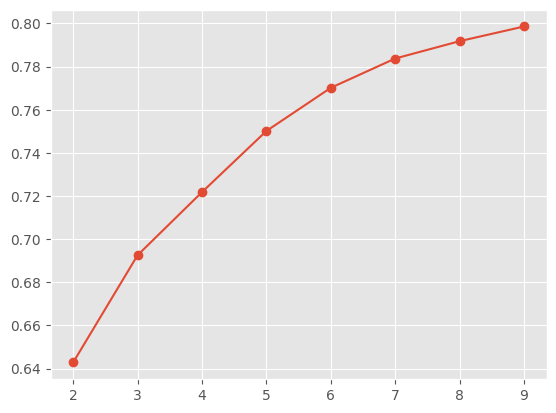

In [13]:
numSubset = 3
allNumArchetypes, expVars = range(2, 10), []
for numArchetypes in allNumArchetypes:
    AAiterative = ArchetypalAnalysis(n_archetypes=numArchetypes, iterative=True, robust=ROBUST, only_archetypes=False, n_subsets=numSubset, shuffle=SHUFFLE, 
                                     C=C, tolerance=TOLERANCE, computeXtX=COMPUTE_XTX, stepsFISTA=STEPS_FISTA, stepsAS=STEPS_AS, randominit=RANDOM_INIT, 
                                     random_state=RANDOM_STATE, numThreads=NUM_JOBS)
    AAiterative.fit(Xscaled)
    expVars.append(AAiterative.explained_variance_)
plt.style.use('ggplot')
plt.plot(allNumArchetypes, expVars, '-o');

### Mapping Data to Archetype Space

We can map the data samples to the convex hull formed by the archetypes using simplex plots.

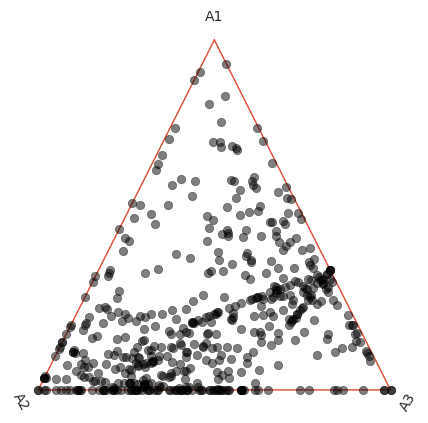

In [15]:
AA.plot_simplex(AA.alfa)

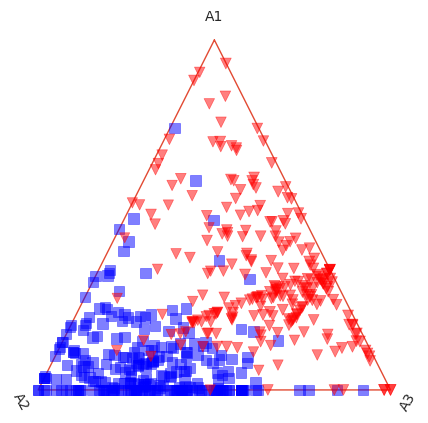

In [16]:
# Users have the flexibility to assign attributes (marker color, marker shape, marker size) to the data samples to enrich the plot.
dfArgs = df[['Gender']].copy()
dfArgs.loc[:, 'color'] = 'red'
dfArgs['color'][dfArgs['Gender']=='female'] = 'blue'

dfArgs.loc[:, 'marker'] = 'v'
dfArgs['marker'][dfArgs['Gender']=='female'] = 's'

dfArgs.loc[:, 'size'] = df[['Height']] / 3

plotArgs = {'color': dfArgs['color'], 's': dfArgs['size'], 'marker': dfArgs['marker']}

AA.plot_simplex(AA.alfa, plotArgs)

Additional utility functions are included to allow more flexibities to create simplex plots and color the data points in different fashions. This requires three steps:
1. Create the simplex plot frame with **create_simplex_ax** utility function.
2. Map the **.alfa** values to the simplex frame using the **map_alfa_to_simplex** utility function.
3. Use standard matplotlib scatter plot to visualise data points.

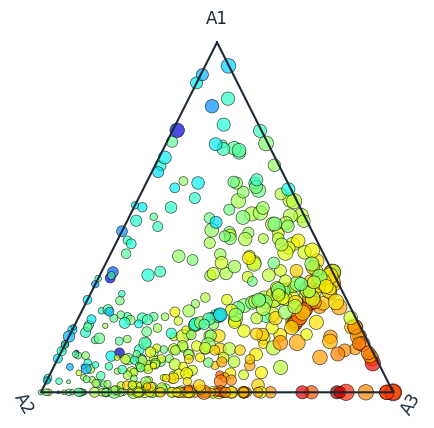

In [17]:
# STEP 1: Create the simplex plot. Users can control the color of gridlines and borders (edges) of the simplex plots. 
create_simplex_ax(AA, grid_on=True, gridcolor='#EAECEE', bordercolor='#1C2833', fontcolor='#1C2833', fig_size=(5, 5))
# STEP 2: Map the alfa values to simplex plot.
mappedAlfa = map_alfa_to_simplex(AA.alfa, AA)
# STEP 3: Use scatter plots to add the mapped alfa to simplex frame.
# The data points are colored by 'Biil' attribute, while sizes are correlated to normalised 'ChestDiam'.
df['ChestDiamNorm'] = (df['ChestDiam'] - df['ChestDiam'].min()) / (df['ChestDiam'].max() - df['ChestDiam'].min())
plt.scatter(mappedAlfa[:,0], mappedAlfa[:,1], 
            c=df['Biil'], cmap='jet', edgecolor='k', 
            s=df['ChestDiamNorm'] * 150, alpha=0.7);

Any other point (e.g. prototypes of clusters) can also be mapped to the simplex plot to compare their relative locations (with other points provided or the overall dataset).

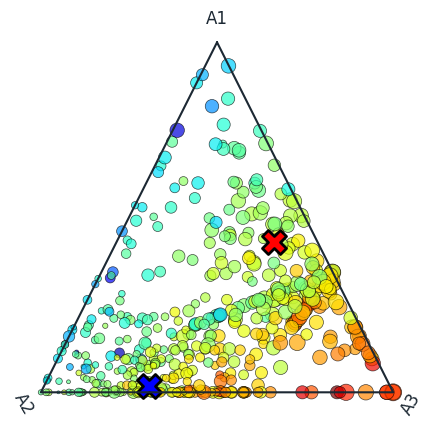

In [18]:
# STEP 1: Get the alpha values for males and females.
XavgMale = Xscaled[df['Gender'] == 'male'].mean(axis=0).reshape(1, -1)
XavgFemale = Xscaled[df['Gender'] == 'female'].mean(axis=0).reshape(1, -1)
_, alfaMale = AA.transform(XavgMale)
_, alfaFemale = AA.transform(XavgFemale)

# STEP 2: Create the simplex plot.
create_simplex_ax(AA, grid_on=True, gridcolor='#EAECEE', bordercolor='#1C2833', fontcolor='#1C2833', fig_size=(5, 5))

# STEP 3: Map the alphas values to the plot.
mappedAlfa = map_alfa_to_simplex(AA.alfa, AA)
mappedAlfaMale = map_alfa_to_simplex(alfaMale, AA)
mappedAlfaFemale = map_alfa_to_simplex(alfaFemale, AA)

# STEP 4: Plot the data samples.
df['ChestDiamNorm'] = (df['ChestDiam']-df['ChestDiam'].min()) / (df['ChestDiam'].max()-df['ChestDiam'].min())
plt.scatter(mappedAlfa[:, 0], mappedAlfa[:, 1], c=df['Biil'], cmap='jet', edgecolor='k', s=df['ChestDiamNorm'] * 150, alpha=0.7);
plt.scatter(mappedAlfaMale[:, 0], mappedAlfaMale[:, 1], marker='X', s=300, color='r', edgecolor='k', linewidth=2);
plt.scatter(mappedAlfaFemale[:, 0], mappedAlfaFemale[:, 1], marker='X', s=300, color='b', edgecolor='k', linewidth=2);

### Visualising Archetype Profiles

The profile of the archetypes can be plot as bar plots or radar plots.

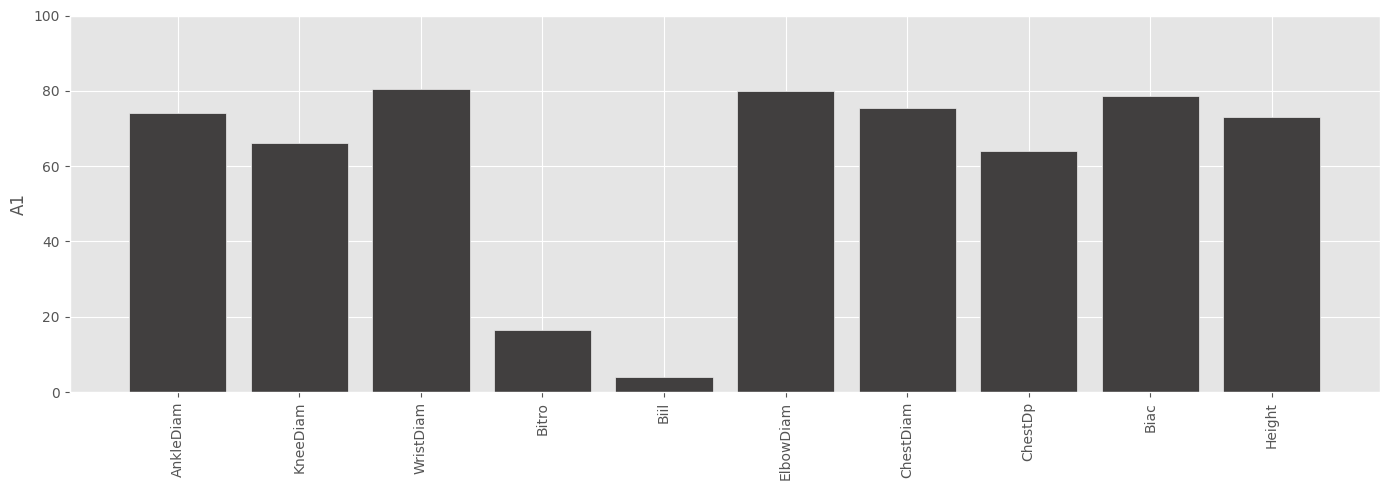

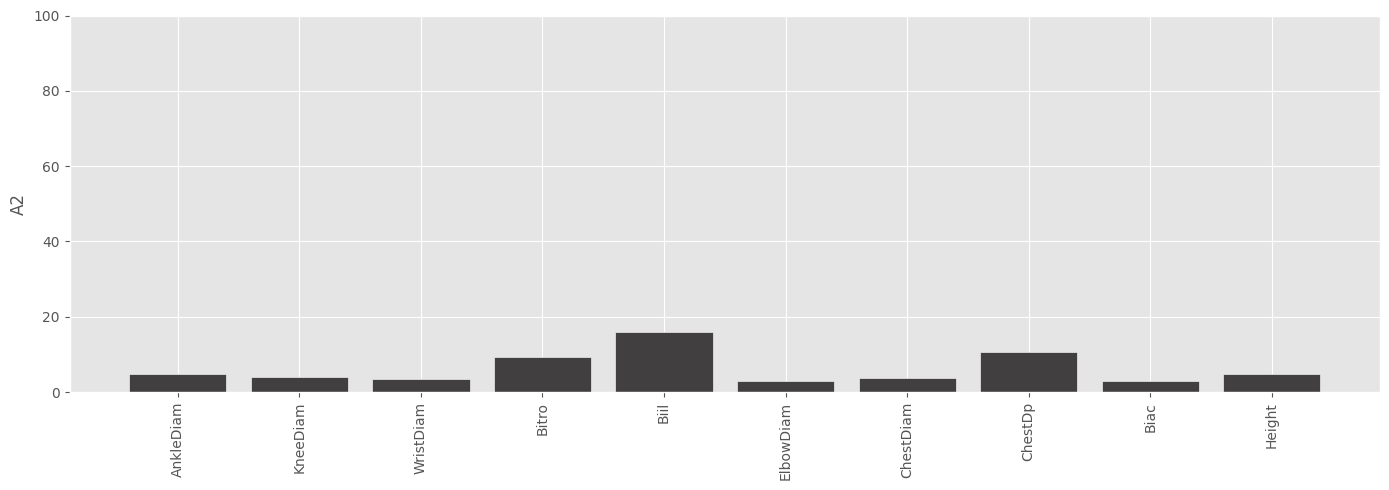

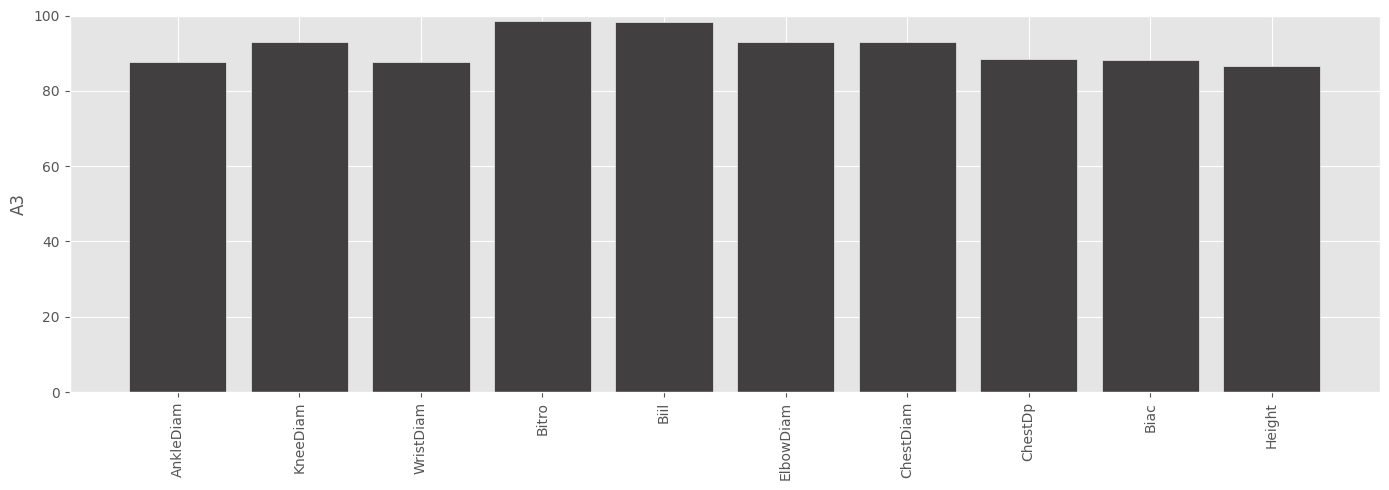

In [19]:
AA.plot_profile(featNames)

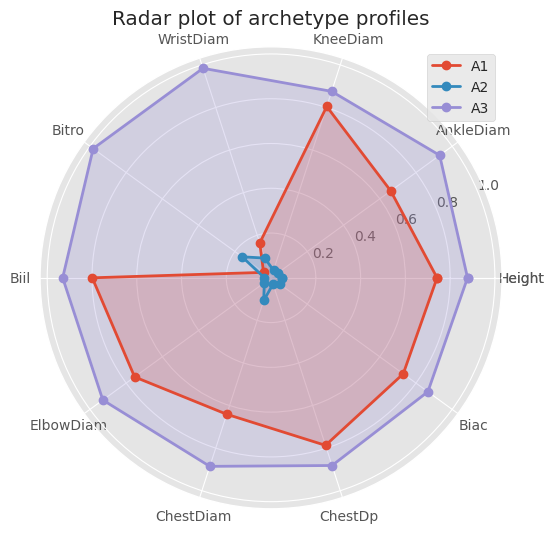

In [20]:
AA.plot_radar_profile(feature_cols=featNames, Title='Radar plot of archetype profiles')

### Identifying Most Archetypal Data Samples

The most archetypal data samples could be identified by running **._extract_close_match()** on the **ArchetypalAnalysis()** object.

Regarding the **.close_match** object:
- The keys are the archetypes.
- The first item in the tuple gives the index of the most archetypal data sample.
- The second item is the corresponding $\alpha$ array of that data point.

The data samples can be mapped to a simplex plot or displayed on a radar plot.

In [21]:
AA._extract_close_match()
AA.close_match

{1: (109, array([0.76479943, 0.09884301, 0.13635756])),
 2: (249, array([0.        , 0.92027823, 0.07972177])),
 3: (144, array([0.10426882, 0.01347575, 0.88225544]))}

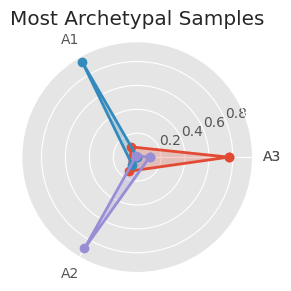

In [22]:
# Radar plot of the most archetypal data samples in the archetype space
AA.plot_close_match(Title='Most Archetypal Samples')

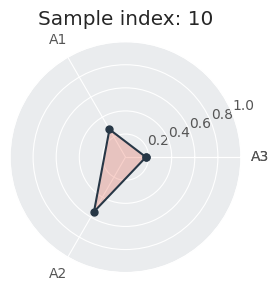

In [23]:
# Any data sample in the archetype space can also be plotted
idx = 10
plot_radar_datapoint(AA, Xscaled[idx, :].reshape(1,-1), Title=f"Sample index: {idx}");

### Visualing Samples and Archetypes on Parallel Axis

The data samples and archetypes could also be plotted on a parallel axis.

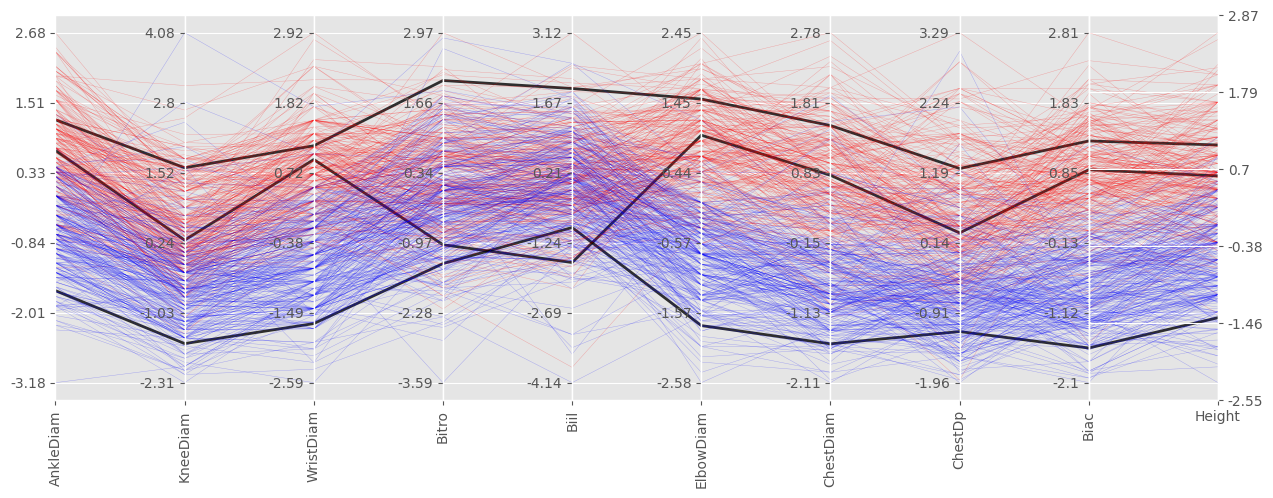

In [24]:
AA.parallel_plot(featNames, dfArgs[['color']].copy(), linewidth='0.3', arch_color='k')